In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("titanic_data.csv")

In [4]:
print(df.shape)
print(df.columns.tolist())



(891, 12)
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [11]:
df["Age"].isnull().sum()

np.int64(0)

In [15]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [16]:
df["Cabin"] = df["Cabin"].fillna("Unknown")


In [17]:
df["Cabin"].isnull().sum()

np.int64(0)

In [15]:
df["Survived"].value_counts().rename({0: "Did not survive", 1: "Survived"})


Survived
Did not survive    549
Survived           342
Name: count, dtype: int64

In [18]:
survival_percent = df["Survived"].mean() * 100
print(f"Overall survival rate: {survival_percent:.2f}%")

Overall survival rate: 38.38%


In [20]:
(df.groupby("Sex")["Survived"].mean() * 100).round(2)

Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

In [24]:
df["Sex"].value_counts(dropna=False)

Sex
male      577
female    314
Name: count, dtype: int64

In [25]:
numeric = df.select_dtypes(include="number")

q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1

outlier_mask = (numeric < q1 - 1.5 * iqr) | (numeric > q3 + 1.5 * iqr)

outlier_counts = outlier_mask.sum()
outlier_counts[outlier_counts > 0]

Age       66
SibSp     46
Parch    213
Fare     116
dtype: int64

In [27]:
cols = ["Age", "SibSp", "Parch", "Fare"]

filtered_df = df.copy()

for col in cols:
    q1 = filtered_df[col].quantile(0.25)
    q3 = filtered_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    filtered_df = filtered_df[
        filtered_df[col].between(lower, upper) | filtered_df[col].isna()
    ]

print("Original rows:", len(df))
print("Rows after filtering:", len(filtered_df))

Original rows: 891
Rows after filtering: 561


In [29]:
# Survival counts by gender
pd.crosstab(df["Sex"], df["Survived"], margins=True)

Survived,0,1,All
Sex,,,
female,81,233,314
male,468,109,577
All,549,342,891


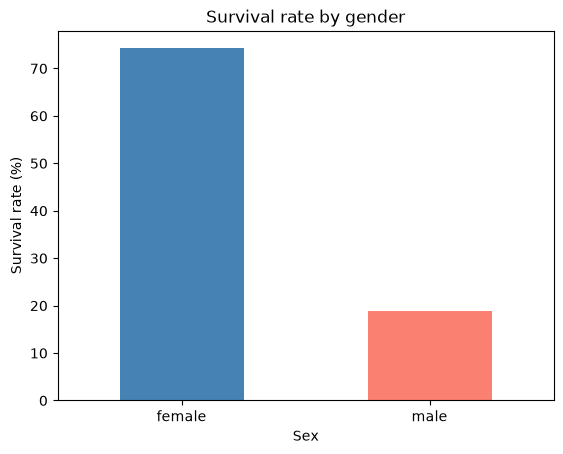

In [32]:
import matplotlib.pyplot as plt

rates = df.groupby("Sex")["Survived"].mean() * 100

rates.plot(kind="bar", color=["steelblue", "salmon"])
plt.ylabel("Survival rate (%)")
plt.title("Survival rate by gender")
plt.xticks(rotation=0)
plt.show()
